<a href="https://colab.research.google.com/github/23wh1a1298/23WH1A1298/blob/main/islabproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import hashlib, hmac, json, os, time, shutil
from pathlib import Path
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt

ALGO  = "sha256"          # try "sha512" or "blake2b" too
CHUNK = 1024 * 1024       # read files in 1 MB chunks (handles huge files)
IGNORE = {".ipynb_checkpoints", "__pycache__", ".git"}
print("Ready ✔  | hash algorithm:", ALGO)

Ready ✔  | hash algorithm: sha256


In [ ]:
def hash_file(path, algo=ALGO):
    """Return the hex digest of a file, read in chunks."""
    h = hashlib.new(algo)
    with open(path, "rb") as f:
        while chunk := f.read(CHUNK):
            h.update(chunk)
    return h.hexdigest()


def scan_directory(root, algo=ALGO):
    """Walk `root` and return {relative_path: {hash, size, mtime}}."""
    root = Path(root).resolve()
    snap = {}
    for p in sorted(root.rglob("*")):
        if p.is_file() and not (set(p.parts) & IGNORE):
            st = p.stat()
            snap[p.relative_to(root).as_posix()] = {
                "hash": hash_file(p, algo), "size": st.st_size, "mtime": st.st_mtime}
    return snap


def _sign(payload, key):
    body = json.dumps(payload, sort_keys=True).encode()
    return hmac.new(key.encode(), body, "sha256").hexdigest()


def save_baseline(snap, path, key, algo=ALGO):
    """Save snapshot as JSON, signed with an HMAC so the baseline itself is tamper-evident."""
    payload = {"algorithm": algo, "created": datetime.now().isoformat(timespec="seconds"), "files": snap}
    with open(path, "w") as f:
        json.dump({"payload": payload, "hmac": _sign(payload, key)}, f, indent=2)
    return payload


def load_baseline(path, key):
    """Load baseline and verify its signature. Raises if the baseline was altered."""
    with open(path) as f:
        data = json.load(f)
    if not hmac.compare_digest(data["hmac"], _sign(data["payload"], key)):
        raise ValueError("🚨 BASELINE FILE HAS BEEN TAMPERED WITH (or wrong key)!")
    return data["payload"]


def compare(baseline_files, current_files):
    """Compare two snapshots and classify every file."""
    rows = []
    for name in sorted(set(baseline_files) | set(current_files)):
        old, new = baseline_files.get(name), current_files.get(name)
        if old and not new:
            status = "DELETED"
        elif new and not old:
            status = "NEW"
        elif old["hash"] != new["hash"]:
            status = "MODIFIED"
        elif old["mtime"] != new["mtime"]:
            status = "TOUCHED"       # timestamp changed, content identical
        else:
            status = "OK"
        rows.append({
            "file": name, "status": status,
            "old_hash": (old["hash"][:16] + "…") if old else "-",
            "new_hash": (new["hash"][:16] + "…") if new else "-",
            "old_size": old["size"] if old else None,
            "new_size": new["size"] if new else None,
        })
    return pd.DataFrame(rows)


def verify(directory, baseline_path, key, show=True):
    """Full integrity check of `directory` against a saved baseline."""
    base = load_baseline(baseline_path, key)
    df = compare(base["files"], scan_directory(directory, base["algorithm"]))
    bad = df[df.status.isin(["MODIFIED", "DELETED", "NEW"])]
    if show:
        print(f"Baseline created: {base['created']}   |   Checked at: {datetime.now():%Y-%m-%d %H:%M:%S}")
        print("✅ INTEGRITY OK – no tampering detected" if bad.empty
              else f"🚨 TAMPERING DETECTED – {len(bad)} suspicious file(s)")
    return df

In [ ]:
DEMO = Path("tamper_demo")
if DEMO.exists(): shutil.rmtree(DEMO)
(DEMO / "docs").mkdir(parents=True)

(DEMO / "notes.txt").write_text("Meeting at 10am.\nBudget approved: 50,000\n")
(DEMO / "config.json").write_text(json.dumps({"user": "guest", "admin": False}, indent=2))
(DEMO / "docs" / "report.csv").write_text("id,amount\n1,100\n2,250\n3,75\n")
(DEMO / "script.py").write_text("print('hello world')\n")
(DEMO / "data.bin").write_bytes(os.urandom(2048))

SECRET_KEY = "change-me-to-a-long-random-secret"   # keep this private in real use
BASELINE   = "baseline.json"

snap = scan_directory(DEMO)
save_baseline(snap, BASELINE, SECRET_KEY)
pd.DataFrame([{"file": k, "sha256": v["hash"][:32] + "…", "size": v["size"]} for k, v in snap.items()])

,file,sha256,size
0,config.json,caf06b83f1a4c77b7485c2f73ba49fa2…,39
1,data.bin,f89b998b02b0b7ae26c57ba51c45c575…,2048
2,docs/report.csv,337f25bbd35af5800761c3af3c7afa91…,27
3,notes.txt,35f87fde17a62061c66867c09e1b7e75…,41
4,script.py,2d543015627a771436b30ea79fd0ecda…,21


In [ ]:
verify(DEMO, BASELINE, SECRET_KEY)

Baseline created: 2026-10-28T14:34:25   |   Checked at: 2026-10-28 14:34:46
✅ INTEGRITY OK – no tampering detected


,file,status,old_hash,new_hash,old_size,new_size
0,config.json,OK,caf06b83f1a4c77b…,caf06b83f1a4c77b…,39,39
1,data.bin,OK,f89b998b02b0b7ae…,f89b998b02b0b7ae…,2048,2048
2,docs/report.csv,OK,337f25bbd35af580…,337f25bbd35af580…,27,27
3,notes.txt,OK,35f87fde17a62061…,35f87fde17a62061…,41,41
4,script.py,OK,2d543015627a7714…,2d543015627a7714…,21,21


In [ ]:
with open(DEMO / "notes.txt", "a") as f:                       # 1. append data
    f.write("Transfer 50,000 to account 9988\n")

cfg = (DEMO / "config.json").read_text().replace("guest", "root")   # 2. same-size edit (4 chars → 4 chars)
cfg = cfg.replace("false", "true ")                                  #    sneaky: keeps file size similar
(DEMO / "config.json").write_text(cfg)

(DEMO / "docs" / "report.csv").unlink()                          # 3. delete a file
(DEMO / "backdoor.sh").write_text("#!/bin/sh\nnc -l 4444\n")    # 4. plant a new file
os.utime(DEMO / "script.py", None)                               # 5. only touch timestamp (content same)
print("Tampering simulated.")

Tampering simulated.


In [ ]:
report = verify(DEMO, BASELINE, SECRET_KEY)

colors = {"MODIFIED": "background-color:#ffb3b3", "DELETED": "background-color:#ffd9a0",
          "NEW": "background-color:#fff3a0", "TOUCHED": "background-color:#d6e4ff",
          "OK": "background-color:#d4f5d4"}
report.style.apply(lambda r: [colors[r.status]] * len(r), axis=1)

Baseline created: 2026-10-28T14:34:25   |   Checked at: 2026-10-28 14:35:18
🚨 TAMPERING DETECTED – 4 suspicious file(s)


,file,status,old_hash,new_hash,old_size,new_size
0,backdoor.sh,NEW,-,58d5362433134f5b…,nan,21.000000
1,config.json,MODIFIED,caf06b83f1a4c77b…,1ab945fe9a847f29…,39.000000,38.000000
2,data.bin,OK,f89b998b02b0b7ae…,f89b998b02b0b7ae…,2048.000000,2048.000000
3,docs/report.csv,DELETED,337f25bbd35af580…,-,27.000000,nan
4,notes.txt,MODIFIED,35f87fde17a62061…,6dcde19828d5ccd2…,41.000000,73.000000
5,script.py,TOUCHED,2d543015627a7714…,2d543015627a7714…,21.000000,21.000000


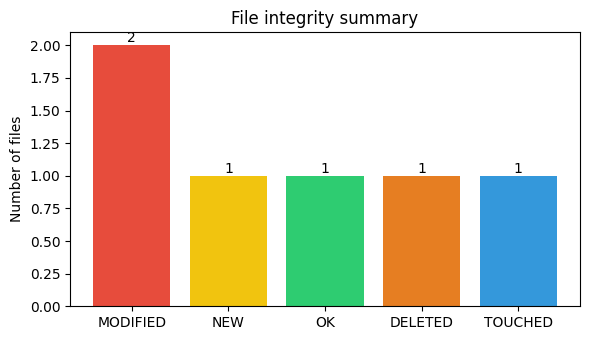

In [ ]:
counts = report.status.value_counts()
plt.figure(figsize=(6, 3.5))
bars = plt.bar(counts.index, counts.values,
               color=[{"MODIFIED":"#e74c3c","DELETED":"#e67e22","NEW":"#f1c40f","TOUCHED":"#3498db","OK":"#2ecc71"}[s] for s in counts.index])
plt.title("File integrity summary"); plt.ylabel("Number of files")
plt.bar_label(bars); plt.tight_layout(); plt.show()

In [ ]:
with open(BASELINE) as f: data = json.load(f)
data["payload"]["files"]["notes.txt"]["hash"] = "0" * 64        # forge a hash
with open("baseline_forged.json", "w") as f: json.dump(data, f)

try:
    load_baseline("baseline_forged.json", SECRET_KEY)
except ValueError as e:
    print(e)

🚨 BASELINE FILE HAS BEEN TAMPERED WITH (or wrong key)!


In [ ]:
a = hashlib.sha256(b"Pay Alice $100").hexdigest()
b = hashlib.sha256(b"Pay Alice $101").hexdigest()      # one character different
diff_bits = bin(int(a, 16) ^ int(b, 16)).count("1")
print("Hash A:", a); print("Hash B:", b)
print(f"\nOne-character change flipped {diff_bits}/256 bits ({diff_bits/256:.0%}) of the hash.")

Hash A: ab95d3cd12811726731fa05f8ee55d4ae3c113b0a1a4b5c0bcff14c4434af031
Hash B: 5a2cdf0e3d060683dc49bc1a0da287ec222a7d1c2e7d9cafab628e806be05cfa

One-character change flipped 130/256 bits (51%) of the hash.


In [ ]:
report.to_csv("tamper_report.csv", index=False)
report.to_json("tamper_report.json", orient="records", indent=2)
print("Saved tamper_report.csv and tamper_report.json  (see the Files panel on the left)")
# from google.colab import files; files.download("tamper_report.csv")   # uncomment to download

Saved tamper_report.csv and tamper_report.json  (see the Files panel on the left)


In [ ]:
# ---- Option A: upload your own files ----
# from google.colab import files
# os.makedirs("my_files", exist_ok=True)
# for name, content in files.upload().items():
#     open(f"my_files/{name}", "wb").write(content)
# save_baseline(scan_directory("my_files"), "my_baseline.json", SECRET_KEY)
# # ...later (after changing/re-uploading files):
# verify("my_files", "my_baseline.json", SECRET_KEY)

# ---- Option B: Google Drive ----
# from google.colab import drive; drive.mount("/content/drive")
# TARGET = "/content/drive/MyDrive/important_folder"
# save_baseline(scan_directory(TARGET), "drive_baseline.json", SECRET_KEY)
# verify(TARGET, "drive_baseline.json", SECRET_KEY)

In [ ]:
def monitor(directory, baseline_path, key, interval=5, rounds=3):
    """Re-check the folder every `interval` seconds and alert on changes."""
    for i in range(rounds):
        df = verify(directory, baseline_path, key, show=False)
        bad = df[df.status.isin(["MODIFIED", "DELETED", "NEW"])]
        stamp = datetime.now().strftime("%H:%M:%S")
        print(f"[{stamp}] check {i+1}/{rounds}: " + ("OK" if bad.empty else "ALERT → " + ", ".join(f"{r.file} ({r.status})" for r in bad.itertuples())))
        time.sleep(interval)

monitor(DEMO, BASELINE, SECRET_KEY, interval=2, rounds=2)

[14:37:24] check 1/2: ALERT → backdoor.sh (NEW), config.json (MODIFIED), docs/report.csv (DELETED), notes.txt (MODIFIED)
[14:37:26] check 2/2: ALERT → backdoor.sh (NEW), config.json (MODIFIED), docs/report.csv (DELETED), notes.txt (MODIFIED)


In [ ]:
s = dict(zip(report.file, report.status))
assert s["notes.txt"] == "MODIFIED"
assert s["config.json"] == "MODIFIED"
assert s["docs/report.csv"] == "DELETED"
assert s["backdoor.sh"] == "NEW"
assert s["script.py"] == "TOUCHED"
assert s["data.bin"] == "OK"
print("All tests passed ✅  – every tampering type was detected correctly.")

All tests passed ✅  – every tampering type was detected correctly.
